# 🍳 PPO Model Visualization and Performance Suite

This unified notebook provides post-training visualization, performance reporting, and evaluation metrics:
1. **Pygame Interactive Rollout:** Graphical simulation of trained agent checkpoints (Cell 1).
2. **Training Curves Plotter:** Grid Search training reward curves over iterations (Cell 2).
3. **Quantitative Model Evaluator:** On-demand multi-episode rollout evaluator and action entropy (Cell 3).
4. **Comparative Analysis & Action Radar:** Bar charts, action distribution breakdowns, and performance tables (Cell 4).
5. **Experiment Log Ranking (JSON):** Ranking table extracted from `experiments/logs/*.json` (Cell 5).
6. **Vision Log Analytics (.log):** Score trajectory over steps, milestone reward peaks, and focus breakdown charts from `experiments/logs/vision_analysis/*.log` (Cell 6).

---  
## 🎮 Cell 1: Pygame Interactive Rollout Simulation (Standalone)
Standalone cell to render the visual behavior of any saved checkpoint in a Pygame window.

In [ ]:
import os
import json
import pygame
import ray
import numpy as np
from pathlib import Path
from collections import defaultdict
from datetime import datetime
from ray.rllib.algorithms.algorithm import Algorithm
from ray.rllib.env.multi_agent_env import MultiAgentEnv
from ray.tune.registry import register_env

try:
    from overcooked_marl_env import OvercookedMARL
except ImportError:
    from env import OvercookedMARL

# Wrapper PettingZoo para RLlib MultiAgentEnv
class ParallelEnvToMultiAgent(MultiAgentEnv):
    def __init__(self, parallel_env):
        self.env = parallel_env
        self.agents = self.env.possible_agents
        super().__init__()
        
    @property
    def observation_space(self):
        return self.env.observation_space

    @property
    def action_space(self):
        return self.env.action_space

    def reset(self, *, seed=None, options=None):
        return self.env.reset(seed=seed, options=options)

    def step(self, action_dict):
        return self.env.step(action_dict)

    def render(self):
        return self.env.render()
    
    def close(self):
        return self.env.close()

    def __getattr__(self, name):
        if name.startswith('_') or name in ['env', 'agents', 'observation_space', 'action_space']:
            raise AttributeError(f"'{type(self).__name__}' object has no attribute '{name}'")
        try:
            env = object.__getattribute__(self, 'env')
            return getattr(env, name)
        except AttributeError:
            raise AttributeError(f"'{type(self).__name__}' object has no attribute '{name}'")

# Configuração central reativa para o criador de ambientes do RLlib
ENVIRONMENT_CONFIG = {
    'map_path': 'default_map.txt',
    'num_fixed_agents': 2,
    'featurized_obs': True
}

def env_creator_fn():
    return OvercookedMARL(
        render_mode=None,
        map_path=ENVIRONMENT_CONFIG['map_path'],
        num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
        verbose=False,
        featurized_obs=ENVIRONMENT_CONFIG['featurized_obs']
    )

def parse_env_params_from_path(checkpoint_path: str):
    """Extrai map_path e num_agents a partir do caminho do trial para alinhar o ambiente."""
    path_obj = Path(checkpoint_path)
    map_path = "default_map.txt"
    num_agents = 2
    
    for part in path_obj.parts:
        if "map-" in part:
            try:
                subparts = part.split('_')
                for sp in subparts:
                    if sp.startswith('map-'):
                        map_name = sp.replace('map-', '')
                        if map_name in ['default', 'default_map']:
                            map_path = 'default_map.txt'
                        else:
                            map_path = f"{map_name}.txt"
            except Exception:
                pass
        if "agents-" in part:
            try:
                subparts = part.split('_')
                for sp in subparts:
                    if sp.startswith('agents-'):
                        num_agents = int(sp.replace('agents-', ''))
            except Exception:
                pass
    return map_path, num_agents

def detect_is_featurized(checkpoint_path: str) -> bool:
    """Lê o params.json do trial correspondente para ver se a rede é MLP (featurized) ou CNN (grid)."""
    checkpoint_dir = Path(checkpoint_path)
    trial_dir = checkpoint_dir.parent
    params_json = trial_dir / "params.json"
    if not params_json.exists():
        params_json = trial_dir.parent / "params.json"
        
    if params_json.exists():
        try:
            with open(params_json, 'r') as f:
                params_data = json.load(f)
                model_config = params_data.get('model', {})
                if 'fcnet_hiddens' in model_config:
                    return True
                if 'conv_filters' in model_config:
                    return False
        except Exception:
            pass
    return True

def load_model_from_checkpoint(checkpoint_path: str) -> Algorithm:
    checkpoint_dir = Path(checkpoint_path)
    if not checkpoint_dir.is_dir():
        raise ValueError(f"Checkpoint path must be a directory: {checkpoint_path}")
    
    rllib_checkpoint_file = checkpoint_dir / "rllib_checkpoint.json"
    if not rllib_checkpoint_file.exists():
        raise FileNotFoundError(f"rllib_checkpoint.json not found in {checkpoint_path}")
    
    try:
        algorithm = Algorithm.from_checkpoint(str(checkpoint_dir))
        if algorithm is None:
            raise RuntimeError("Failed to load algorithm from checkpoint")
        return algorithm
    except Exception as e:
        raise RuntimeError(f"Failed to load model: {e}")

def visualize_model_behavior(checkpoint_path: str, num_episodes: int = 1, max_steps: int = 800):
    # 1. Extrair os parâmetros de ambiente originais do checkpoint
    map_path, num_agents = parse_env_params_from_path(checkpoint_path)
    is_featurized = detect_is_featurized(checkpoint_path)
    
    # 2. Atualizar dicionário global antes do carregamento e registrar env
    ENVIRONMENT_CONFIG['map_path'] = map_path
    ENVIRONMENT_CONFIG['num_fixed_agents'] = num_agents
    ENVIRONMENT_CONFIG['featurized_obs'] = is_featurized
    
    print(f"[INFO] Registrando ambiente: map={map_path}, agents={num_agents}, featurized={is_featurized}")
    register_env("overcooked_marl_parallel", lambda config: ParallelEnvToMultiAgent(env_creator_fn()))
    
    # 3. Carregar o algoritmo com os workers inicializados corretamente
    algorithm = load_model_from_checkpoint(checkpoint_path)
    
    agent_policies = {}
    for agent_id in ["agent_0", "agent_1", "agent_2", "agent_3"]:
        policy = None
        try:
            policy = algorithm.get_policy(f"policy_{agent_id}")
        except Exception:
            try:
                policy = algorithm.get_policy("shared_policy")
            except Exception:
                try:
                    if hasattr(algorithm, 'workers') and algorithm.workers:
                        worker = algorithm.workers.local_worker()
                        policy = worker.get_policy(f"policy_{agent_id}") or worker.get_policy("shared_policy")
                except Exception:
                    pass
        if policy is not None:
            agent_policies[agent_id] = policy

    if not agent_policies:
        raise RuntimeError("Could not retrieve any policies from the checkpoint.")
    
    # 4. Criar ambiente gráfico Pygame para visualização
    env = ParallelEnvToMultiAgent(OvercookedMARL(
        render_mode="human",
        map_path=ENVIRONMENT_CONFIG['map_path'],
        num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
        verbose=False,
        featurized_obs=ENVIRONMENT_CONFIG['featurized_obs']
    ))
    
    try:
        for episode in range(num_episodes):
            obs_dict, infos = env.reset()
            episode_reward = 0.0
            
            for step in range(max_steps):
                actions = {}
                for agent_id in env.agents:
                    try:
                        obs = obs_dict[agent_id]
                        if not isinstance(obs, np.ndarray):
                            obs = np.array(obs)
                        obs_for_model = obs.astype(np.float32) if is_featurized else obs.astype(np.uint8)
                        
                        policy = agent_policies.get(agent_id) or list(agent_policies.values())[0]
                        action, _, _ = policy.compute_single_action(obs=obs_for_model, explore=True)
                        
                        if isinstance(action, (np.ndarray, list)):
                            action = int(action[0] if len(action) > 0 else action)
                        else:
                            action = int(action)
                        actions[agent_id] = action
                    except Exception:
                        actions[agent_id] = env.action_space[agent_id].sample()
                
                obs_dict, rewards, terminations, truncations, infos = env.step(actions)
                episode_reward += sum(rewards.values())
                env.render()
                
                # Delay de visualização
                pygame.time.wait(10)  # Acelerado
                
                if terminations.get('__all__', False) or truncations.get('__all__', False):
                    break
            print(f"[RESULT] Episode {episode+1} finished. Reward: {episode_reward:.2f}")
    finally:
        env.close()

def discover_checkpoints(ray_results_dir="ray_results"):
    checkpoints = []
    results_path = Path(ray_results_dir).resolve()
    if not results_path.exists():
        return checkpoints
        
    for cp_path in results_path.glob("**/checkpoint_*"):
        if cp_path.is_dir() and (cp_path / "rllib_checkpoint.json").exists():
            try:
                model_info_path = cp_path.parents[1] / "model_info.json"
                avg_reward = 0.0
                if model_info_path.exists():
                    with open(model_info_path, 'r') as f:
                        meta = json.load(f)
                        avg_reward = meta.get('avg_reward', 0.0)
                checkpoints.append((cp_path, avg_reward))
            except Exception:
                checkpoints.append((cp_path, 0.0))
                
    checkpoints.sort(key=lambda x: (x[1], int(x[0].name.split('_')[-1]) if x[0].name.split('_')[-1].isdigit() else 0), reverse=True)
    return [cp[0] for cp in checkpoints]

ray.init(ignore_reinit_error=True)
print("Scaneando checkpoints na pasta ray_results/...")
cps = discover_checkpoints()
if cps:
    print(f"Encontrados {len(cps)} checkpoints.")
        
    best_cp = str(cps[0])
    visualize_model_behavior(
        checkpoint_path=best_cp,
        num_episodes=1
    )
else:
    print("[WARN] Nenhum checkpoint encontrado em ray_results/.")


---  
## 📈 Cell 2: Training Curve Plotter (Grid Search)
Reads saved training metadata (`model_info.json`) and renders episode mean reward curves.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

def plot_grid_search_curves(ray_results_dir="ray_results"):
    results_path = Path(ray_results_dir).resolve()
    all_runs = []
    
    for model_info_file in results_path.glob("**/model_info.json"):
        try:
            with open(model_info_file, 'r') as f:
                data = json.load(f)
                
            config_name = data.get('config_name', model_info_file.parent.name)
            learning_curves = data.get('learning_curves', [])
            
            for point in learning_curves:
                all_runs.append({
                    'Config': config_name,
                    'Iteration': point['iteration'],
                    'Mean Reward': point['reward_mean']
                })
        except Exception as e:
            print(f"Erro lendo {model_info_file.name}: {e}")
            
    if not all_runs:
        print(f"Nenhum arquivo model_info.json encontrado sob: {results_path}")
        return
        
    df = pd.DataFrame(all_runs)
    
    plt.figure()
    sns.lineplot(data=df, x='Iteration', y='Mean Reward', hue='Config', marker="o")
    plt.title("PPO Split-Policy Multi-Agent Training Curves (MLP DNN)", fontsize=14, fontweight='bold')
    plt.xlabel("Training Iteration", fontsize=12)
    plt.ylabel("Episode Mean Reward (Scaled)", fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

plot_grid_search_curves("ray_results")


---  
## 🔬 Cell 3: On-Demand Quantitative Model Evaluator
Executes fast non-graphical evaluation rollouts over multiple episodes to compute average rewards, recipe deliveries, and action distributions.

In [ ]:
import torch
import csv

def discover_ray_checkpoints_eval(ray_results_dir="ray_results"):
    models = []
    ray_results_path = Path(ray_results_dir).resolve()
    
    if not ray_results_path.exists():
        return models
    
    timestamp_dirs = [d for d in ray_results_path.iterdir() if d.is_dir() and d.name.startswith('PPO_Marl_')]
    for timestamp_dir in timestamp_dirs:
        exp_dirs = [d for d in timestamp_dir.iterdir() if d.is_dir()]
        for exp_dir in exp_dirs:
            if exp_dir.name.startswith('PPO_Marl_Config_'):
                process_exp_dir = exp_dir
                parent_dir = timestamp_dir
                config_num = process_exp_dir.name.split('_')[-1]
                config_name = f"PPO_Config_{config_num:0>2}"
            elif exp_dir.name.startswith('PPO_Marl_'):
                process_exp_dir = exp_dir
                parent_dir = exp_dir
                params_part = exp_dir.name.replace('PPO_Marl_', '')
                config_name = f"PPO_Config_{params_part}"
            else:
                continue
            
            def find_trial_directory(base_dir):
                for d in base_dir.iterdir():
                    if d.is_dir() and d.name.startswith('PPO_overcooked_marl_parallel_'):
                        return d
                for d in base_dir.iterdir():
                    if d.is_dir():
                        if (d / "progress.csv").exists() or (d / "params.json").exists():
                            return d
                if (base_dir / "progress.csv").exists() or (base_dir / "params.json").exists():
                    return base_dir
                return None
            
            trial_dir = find_trial_directory(process_exp_dir)
            if not trial_dir:
                continue
            
            checkpoint_dirs = [d for d in trial_dir.iterdir() if d.is_dir() and d.name.startswith('checkpoint_')]
            if not checkpoint_dirs:
                continue
            
            checkpoint_dirs.sort(key=lambda x: int(x.name.split('_')[-1]) if x.name.split('_')[-1].isdigit() else 0, reverse=True)
            latest_checkpoint_dir = checkpoint_dirs[0]
            checkpoint_path = str(latest_checkpoint_dir.resolve())
            
            training_reward = 0.0
            progress_csv = trial_dir / "progress.csv"
            if progress_csv.exists():
                try:
                    with open(progress_csv, 'r') as f:
                        reader = csv.DictReader(f)
                        rows = list(reader)
                        if rows:
                            last_row = rows[-1]
                            reward_key = 'env_runners/episode_reward_mean'
                            if reward_key in last_row and last_row[reward_key]:
                                training_reward = float(last_row[reward_key])
                except Exception:
                    pass
            
            params = {}
            training_config = {}
            model_info_path = parent_dir / "model_info.json"
            if model_info_path.exists():
                try:
                    with open(model_info_path, 'r') as f:
                        model_info = json.load(f)
                        params = model_info.get('params', {})
                        training_config = model_info.get('training_config', {})
                except Exception:
                    pass
            
            models.append({
                'checkpoint_path': checkpoint_path,
                'model_dir': str(trial_dir.resolve()),
                'config_name': config_name,
                'model_name': latest_checkpoint_dir.name,
                'training_reward': float(training_reward),
                'params': params,
                'training_config': training_config,
                'source': 'ray_results'
            })
    models.sort(key=lambda x: x.get('training_reward', 0.0), reverse=True)
    return models

def evaluate_model(checkpoint_path: str, num_episodes: int = 5, max_steps: int = 800) -> dict:
    # Extrair map_path e num_agents do checkpoint
    map_path, num_agents = parse_env_params_from_path(checkpoint_path)
    is_featurized = detect_is_featurized(checkpoint_path)
    
    # Garantir o registro com os parâmetros corretos para o carregador
    ENVIRONMENT_CONFIG['map_path'] = map_path
    ENVIRONMENT_CONFIG['num_fixed_agents'] = num_agents
    ENVIRONMENT_CONFIG['featurized_obs'] = is_featurized
    register_env("overcooked_marl_parallel", lambda config: ParallelEnvToMultiAgent(env_creator_fn()))

    algorithm = load_model_from_checkpoint(checkpoint_path)
    
    agent_policies = {}
    for agent_id in ["agent_0", "agent_1", "agent_2", "agent_3"]:
        policy = None
        try:
            policy = algorithm.get_policy(f"policy_{agent_id}")
        except Exception:
            try:
                policy = algorithm.get_policy("shared_policy")
            except Exception:
                try:
                    if hasattr(algorithm, 'workers') and algorithm.workers:
                        worker = algorithm.workers.local_worker()
                        policy = worker.get_policy(f"policy_{agent_id}") or worker.get_policy("shared_policy")
                except Exception:
                    pass
        if policy is not None:
            agent_policies[agent_id] = policy

    if not agent_policies:
        raise RuntimeError("Could not load policy.")
    
    # Criar ambiente sob demanda para avaliação quantitativa
    env = ParallelEnvToMultiAgent(OvercookedMARL(
        render_mode=None,
        map_path=ENVIRONMENT_CONFIG['map_path'],
        num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
        verbose=False,
        featurized_obs=ENVIRONMENT_CONFIG['featurized_obs']
    ))
    
    episode_rewards = []
    episode_lengths = []
    deliveries_per_episode = []
    action_counts = defaultdict(int)
    success_episodes = 0
    
    for episode in range(num_episodes):
        obs_dict, infos = env.reset()
        episode_reward = 0.0
        episode_length = 0
        
        initial_delivered = 0
        if "agent_0" in infos and isinstance(infos["agent_0"], dict):
            initial_delivered = len(infos["agent_0"].get('delivered_recipes', []))
        
        for step in range(max_steps):
            actions = {}
            for agent_id in env.agents:
                try:
                    obs = obs_dict[agent_id]
                    if not isinstance(obs, np.ndarray):
                        obs = np.array(obs)
                    obs_for_model = obs.astype(np.float32) if is_featurized else obs.astype(np.uint8)
                    
                    policy = agent_policies.get(agent_id) or list(agent_policies.values())[0]
                    action, _, _ = policy.compute_single_action(obs=obs_for_model, explore=True)
                    if isinstance(action, (np.ndarray, list)):
                        action = int(action[0] if len(action) > 0 else action)
                    else:
                        action = int(action)
                    actions[agent_id] = action
                except Exception:
                    actions[agent_id] = env.action_space[agent_id].sample()
            
            obs_dict, rewards, terminations, truncations, infos = env.step(actions)
            episode_reward += sum(rewards.values())
            for act in actions.values():
                action_counts[int(act)] += 1
            episode_length += 1
            
            if terminations.get('__all__', False) or truncations.get('__all__', False):
                break
        
        final_delivered = 0
        if "agent_0" in infos and isinstance(infos["agent_0"], dict):
            final_delivered = len(infos["agent_0"].get('delivered_recipes', []))
        
        episode_deliveries = final_delivered - initial_delivered
        episode_rewards.append(episode_reward)
        episode_lengths.append(episode_length)
        deliveries_per_episode.append(episode_deliveries)
        if episode_deliveries > 0:
            success_episodes += 1
            
    env.close()
    
    total_actions = sum(action_counts.values())
    action_distribution = {a: count / total_actions for a, count in action_counts.items()} if total_actions > 0 else {}
    
    return {
        'checkpoint_path': checkpoint_path,
        'eval_rewards': episode_rewards,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'mean_deliveries': np.mean(deliveries_per_episode),
        'success_rate': success_episodes / num_episodes,
        'action_distribution': action_distribution,
        'action_entropy': -sum(p * np.log(p + 1e-10) for p in action_distribution.values()) if action_distribution else 0.0,
        'interaction_frequency': action_distribution.get(4, 0.0)
    }

print("Buscando checkpoints salvos para avaliação...")
discovered = discover_ray_checkpoints_eval()
evaluation_results = []

for idx, model in enumerate(discovered):  # Limita aos top 3 para avaliação rápida
    print(f"Avaliando quantitativamente {model['config_name']}...")
    try:
        res = evaluate_model(model['checkpoint_path'], num_episodes=5)
        res.update({
            'config_name': model['config_name'],
            'training_reward': model['training_reward'],
            'params': model['params'],
            'training_config': model['training_config'],
            'model_dir': model['model_dir']
        })
        evaluation_results.append(res)
    except Exception as e:
        print(f"Erro avaliando checkpoint {model['config_name']}: {e}")


---  
## 📊 Cell 4: Comparative Performance & Action Radar Analysis
Plots bar charts of action frequencies, checkpoint rankings by delivery rate, and comparative summary tables.

In [ ]:
def generate_model_display_name(model_dict: dict, max_length: int = 80, use_full_name: bool = False) -> str:
    checkpoint_path = model_dict.get('checkpoint_path', '')
    if checkpoint_path:
        try:
            parts = Path(checkpoint_path).parts
            for part in parts:
                if part.startswith('PPO_Marl_') and not part.startswith('PPO_Marl_Config_'):
                    if 'lr' in part or 'gamma' in part or 'entropy' in part:
                        return part
        except Exception:
            pass
    return model_dict.get('config_name', 'Model')

def generate_analysis_plots(evaluation_results: list):
    if not evaluation_results:
        print("Sem resultados para visualizar!")
        return
        
    df = pd.DataFrame(evaluation_results)
    df = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
    
    # 1. Ranking de Modelos por Entregas de Receitas
    fig, ax = plt.subplots(figsize=(10, 5))
    df_top = df.head(5)
    names = [generate_model_display_name(row.to_dict()) for _, row in df_top.iterrows()]
    sns.barplot(x=df_top['mean_deliveries'], y=names, palette='viridis', ax=ax)
    ax.set_title("Ranking de Modelos por Entregas Médias", fontsize=14, fontweight='bold')
    ax.set_xlabel("Entregas Médias por Episódio")
    plt.tight_layout()
    plt.show()
    
    # 2. Distribuição de Ações (Especialização de Tarefas)
    fig, axes = plt.subplots(1, min(3, len(df)), figsize=(15, 4))
    if len(df) == 1:
        axes = [axes]
    action_names = ['UP', 'DOWN', 'LEFT', 'RIGHT', 'INTERACT']
    for i in range(min(3, len(df))):
        row = df.iloc[i]
        dist = row['action_distribution']
        values = [dist.get(j, 0.0) * 100 for j in range(5)]
        axes[i].bar(action_names, values, color=plt.cm.Set2(range(5)))
        axes[i].set_title(row['config_name'], fontsize=11, fontweight='bold')
        axes[i].set_ylabel("Frequência (%)")
        axes[i].grid(True, alpha=0.3)
    plt.suptitle("Distribuição de Ações (Ações Principais)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 3. Tabela Comparativa Corrente
    print("\n" + "="*90)
    print(" TABELA COMPARATIVA DE PERFORMANCE (TOP MODELOS)")
    print("="*90)
    for idx, row in df.iterrows():
        print(f"{idx+1}. {row['config_name']} | Reward Médio: {row['mean_reward']:.2f} | Entregas: {row['mean_deliveries']:.2f} | Sucesso: {row['success_rate']*100:.1f}%")
    print("="*90 + "\n")

if evaluation_results:
    generate_analysis_plots(evaluation_results)


---  
## 📂 Cell 5: Experiment Log Summary & Ranking (experiments/logs/*.json)
Extracts experiment metrics and hyperparameters directly from `experiments/logs/*.json` files.

In [ ]:
import json
import pandas as pd
from pathlib import Path
from collections import defaultdict
from IPython.display import display

def parse_experiment_logs(logs_dir="logs"):
    logs_path = Path(logs_dir).resolve()
    if not logs_path.exists():
        logs_path = Path("experiments/logs").resolve()
        
    records = []
    for json_file in logs_path.glob("*.json"):
        try:
            with open(json_file, "r") as f:
                data = json.load(f)
                
            exp_name = data.get("ray_results_folder", json_file.stem)
            hyperparams = data.get("hyperparameters", {})
            eval_data = data.get("evaluation", {}) or (data if "reward_mean" in data else {})
            
            records.append({
                "Log File": json_file.name,
                "Experiment Name": exp_name,
                "Training Reward": data.get("training_reward_mean", None),
                "Eval Mean Reward": eval_data.get("reward_mean", None),
                "Eval Std": eval_data.get("reward_std", None),
                "Mean Deliveries": eval_data.get("deliveries_mean", None),
                "Mean Steps": eval_data.get("steps_mean", None),
                "Checkpoint": eval_data.get("checkpoint_path", data.get("checkpoint_path", "N/A")),
                "Hyperparameters": hyperparams
            })
        except Exception as e:
            print(f"Erro lendo {json_file.name}: {e}")
            
    if records:
        df = pd.DataFrame(records)
        if "Eval Mean Reward" in df.columns:
            df = df.sort_values(by="Eval Mean Reward", ascending=False).reset_index(drop=True)
        return df
    return pd.DataFrame()

def parse_vision_analysis_logs(vision_dir="logs/vision_analysis"):
    v_path = Path(vision_dir).resolve()
    if not v_path.exists():
        v_path = Path("experiments/logs/vision_analysis").resolve()
        
    log_stats = []
    for log_file in v_path.glob("*.log"):
        focus_counts = defaultdict(int)
        total_steps = 0
        final_score = 0.0
        
        try:
            with open(log_file, "r") as f:
                for line in f:
                    if "[Step " in line and "Focus:" in line:
                        total_steps += 1
                        parts = line.split("|")
                        for p in parts:
                            if "Focus:" in p:
                                focus_item = p.split("Focus:")[1].strip().split("(")[0].strip()
                                focus_counts[focus_item] += 1
                            elif "Score:" in p:
                                try:
                                    final_score = float(p.split("Score:")[1].strip())
                                except Exception:
                                    pass
            top_focus = max(focus_counts.items(), key=lambda x: x[1])[0] if focus_counts else "N/A"
            log_stats.append({
                "Vision Log File": log_file.name,
                "Logged Steps": total_steps,
                "Final Score": final_score,
                "Primary Focus": top_focus,
                "Focus Breakdown": dict(focus_counts)
            })
        except Exception as e:
            print(f"Erro lendo {log_file.name}: {e}")
            
    if log_stats:
        return pd.DataFrame(log_stats)
    return pd.DataFrame()

print("="*80)
print(" 📂 RANKING DOS EXPERIMENTOS EXTRAÍDO DE experiments/logs/*.json")
print("="*80)
df_logs = parse_experiment_logs("logs")
if not df_logs.empty:
    display(df_logs)
else:
    print("Nenhum log de experimento JSON encontrado em experiments/logs/")

print("\n" + "="*80)
print(" 🔍 ANÁLISE DOS LOGS DE VISÃO EM experiments/logs/vision_analysis/*.log")
print("="*80)
df_vision = parse_vision_analysis_logs("logs/vision_analysis")
if not df_vision.empty:
    display(df_vision)
else:
    print("Nenhum log de visão (.log) encontrado em experiments/logs/vision_analysis/")


---  
## 👁️ Cell 6: Vision Analysis Log Plotter (experiments/logs/vision_analysis/*.log)
Plots step-by-step score trajectories, milestone reward peaks, and agent focus distribution from `.log` files.

[INFO] Carregando e analisando o log de visão: vision_analysis_PPO_Marl_20260923_213853.log


/tmp/ipykernel_147618/4120527072.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=focus_counts.values, y=focus_counts.index, ax=axes[1], palette="viridis")


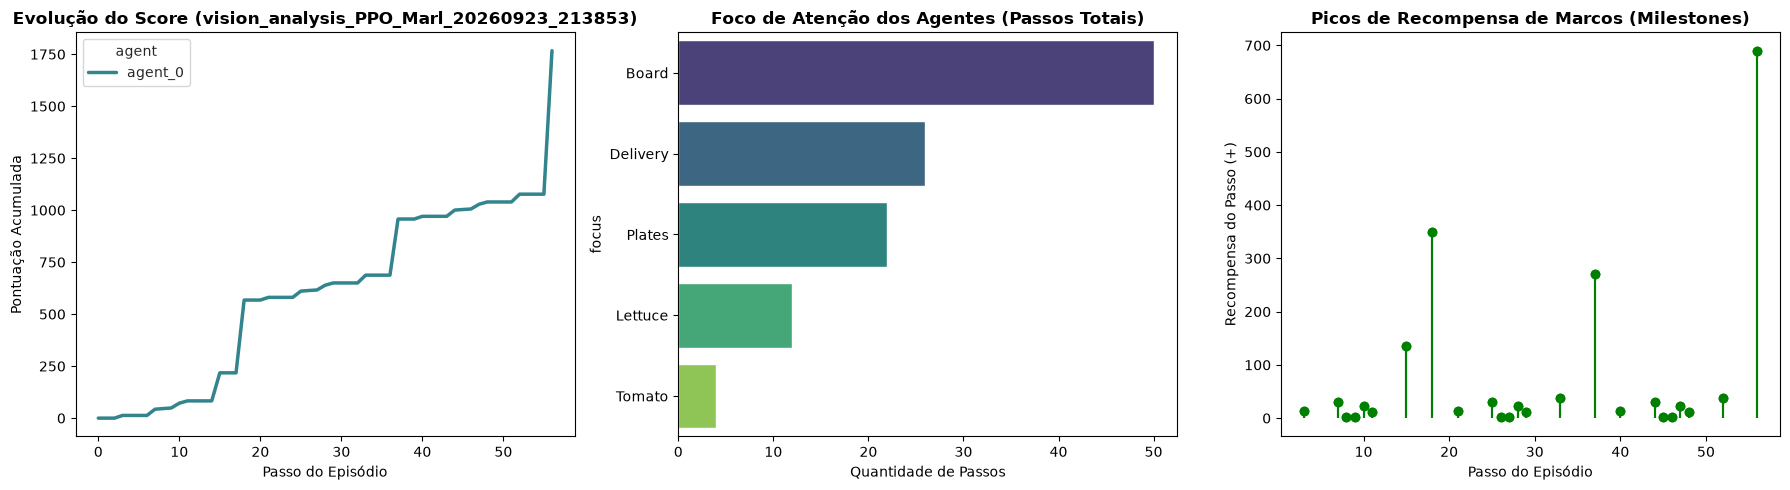

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

def plot_vision_log_analysis(vision_log_path=None):
    log_dir = Path("experiments/logs/vision_analysis").resolve()
    if not log_dir.exists():
        log_dir = Path("logs/vision_analysis").resolve()
        
    target_file = None
    if vision_log_path:
        target_file = Path(vision_log_path)
    else:
        logs = sorted(list(log_dir.glob("*.log")), key=lambda p: p.stat().st_mtime, reverse=True)
        if logs:
            target_file = logs[0]
            
    if not target_file or not target_file.exists():
        print(f"[WARN] Nenhum arquivo .log de visão encontrado em: {log_dir}")
        return
        
    print(f"[INFO] Carregando e analisando o log de visão: {target_file.name}")
    
    records = []
    with open(target_file, "r") as f:
        for line in f:
            if "[Step " in line and "Focus:" in line:
                try:
                    step_match = re.search(r"\[Step (\d+)\]", line)
                    agent_match = re.search(r"\] (\w+_\d+|\w+) \|", line)
                    focus_match = re.search(r"Focus:\s*([^\|]+)", line)
                    score_match = re.search(r"Score:\s*([\+\-\d\.]+)", line)
                    step_rwd_match = re.search(r"Step Rwd:\s*([\+\-\d\.]+)", line)
                    hold_match = re.search(r"Hold:\s*([^\|]+)", line)
                    
                    step = int(step_match.group(1)) if step_match else 0
                    agent = agent_match.group(1) if agent_match else "agent_0"
                    focus_str = focus_match.group(1).strip() if focus_match else "Unknown"
                    score = float(score_match.group(1)) if score_match else 0.0
                    step_rwd = float(step_rwd_match.group(1)) if step_rwd_match else 0.0
                    hold = hold_match.group(1).strip() if hold_match else "empty"
                    
                    focus_clean = focus_str.split("(")[0].strip()
                    
                    records.append({
                        "step": step,
                        "agent": agent,
                        "focus": focus_clean,
                        "score": score,
                        "step_reward": step_rwd,
                        "holding": hold
                    })
                except Exception:
                    pass
                    
    if not records:
        print(f"[WARN] Nenhum registro formatado encontrado em {target_file.name}")
        return
        
    df = pd.DataFrame(records)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.set_style("whitegrid")
    
    # 1. Trajetória de Score Acumulado ao Longo do Episódio
    sns.lineplot(data=df, x="step", y="score", hue="agent", ax=axes[0], linewidth=2.5, palette="crest")
    axes[0].set_title(f"Evolução do Score ({target_file.stem})", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Passo do Episódio")
    axes[0].set_ylabel("Pontuação Acumulada")
    
    # 2. Distribuição do Foco de Atenção dos Agentes
    focus_counts = df["focus"].value_counts()
    sns.barplot(x=focus_counts.values, y=focus_counts.index, ax=axes[1], palette="viridis")
    axes[1].set_title("Foco de Atenção dos Agentes (Passos Totais)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Quantidade de Passos")
    
    # 3. Picos de Recompensa de Marcos (Milestones > 0)
    milestones = df[df["step_reward"] > 0]
    if not milestones.empty:
        axes[2].stem(milestones["step"], milestones["step_reward"], linefmt="g-", markerfmt="go", basefmt=" ")
        axes[2].set_title("Picos de Recompensa de Marcos (Milestones)", fontsize=12, fontweight="bold")
        axes[2].set_xlabel("Passo do Episódio")
        axes[2].set_ylabel("Recompensa do Passo (+)")
    else:
        axes[2].text(0.5, 0.5, "Sem recompensas positivas registradas", ha="center", va="center")
        axes[2].set_title("Picos de Recompensa de Marcos", fontsize=12, fontweight="bold")
        
    plt.tight_layout()
    plt.show()
    
plot_vision_log_analysis()
